# Bacterial Population Growth: Differential Equations and Scientific Computing

### A beginner-friendly Python investigation using the logistic growth model

**Level:** First-year Mathematics degree  
**Topics:** Ordinary differential equations (ODEs), analytical solutions, numerical methods, parameter estimation, data visualization and scientific computing.

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Formulate a population-growth problem as a first-order ordinary differential equation.
2. Explain the meaning of the parameters in the logistic growth model.
3. Derive and use the analytical solution of the logistic equation.
4. Generate simulated observations with measurement noise.
5. Estimate unknown model parameters from data using nonlinear least squares.
6. implement Euler's method to approximate an ODE solution.
7. Compare numerical approximations with an analytical solution.
8. Calculate when the population reaches a specified proportion of its carrying capacity.

## The scientific problem

Imagine that a scientist places an initial population of **40 bacteria** in a controlled laboratory environment. The bacteria reproduce, but nutrients and physical space are limited. Therefore, the population cannot increase indefinitely.

We want to investigate:

- How does the bacterial population change with time?
- What is the maximum population that the environment can support?
- Can we estimate the growth parameters from observed data?
- How accurately can Euler's method approximate the solution?

We will use a mathematical model, generate simulated experimental observations, estimate unknown parameters and perform numerical simulations.

> **Important:** The observations in this notebook are artificially generated from a known mathematical model, with random noise added to imitate measurement errors. They are not actual laboratory data.

---

## Step 0. Install the required Python libraries

We use three Python libraries:

| Library | Purpose |
|---|---|
| NumPy | Numerical calculations, arrays and mathematical functions |
| Matplotlib | Plotting graphs and visualizing results |
| SciPy | Scientific computing, including nonlinear parameter estimation |

The installation command below is written for a Jupyter Notebook. The `%` symbol makes it a notebook magic command.

Run this cell once if the libraries are not already installed in your Python environment.

In [1]:
%pip install numpy matplotlib scipy

---

# Step 1. Formulate the mathematical model

## 1.1 The logistic growth equation

A simple model of unrestricted population growth is exponential growth:

$$
\frac{dP}{dt}=rP.
$$

Here:

- $P(t)$ is the population at time $t$.
- $r$ is the intrinsic growth rate.
- $t$ represents time.

This model assumes that the population can continue growing without any limitation. However, a real bacterial culture has limited nutrients and space.

To account for these limitations, we introduce the **logistic growth model**:

$$
\boxed{\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right)}
$$

with the initial condition

$$
\boxed{P(0)=P_0=40.}
$$

The parameters are:

| Symbol | Meaning | Value or interpretation |
|---|---|---|
| $P(t)$ | Bacterial population at time $t$ | Unknown function |
| $P_0$ | Initial population | 40 |
| $r$ | Intrinsic growth rate | 0.35 per day in our simulated example |
| $K$ | Carrying capacity | 800 in our simulated example |
| $t$ | Time | Measured in days |

The carrying capacity $K$ represents the population level that the environment can sustain in this simplified model.

## 1.2 Understanding the two factors

The right-hand side of the equation contains two factors:

$$
\frac{dP}{dt}
=
\underbrace{rP}_{\text{potential growth}}
\underbrace{\left(1-\frac{P}{K}\right)}_{\text{resource limitation}}.
$$

**First factor: $rP$**

This represents the potential growth rate. If the population is larger, more bacteria are available to reproduce.

**Second factor: $1-P/K$**

This represents the limitation caused by available resources.

Consider three situations:

1. When $P$ is much smaller than $K$, the limiting factor is close to 1. Growth is approximately exponential.
2. When $P$ approaches $K$, the limiting factor approaches 0. Growth slows down.
3. When $P=K$, the growth rate is zero.

At equilibrium,

$$
rP\left(1-\frac{P}{K}\right)=0.
$$

Therefore, the equilibrium populations are

$$
\boxed{P=0 \quad \text{or} \quad P=K.}
$$

For a positive initial population, the model predicts that the population approaches $K$.

## 1.3 What type of differential equation is this?

The logistic model is:

- An ordinary differential equation (ODE), because it involves an ordinary derivative with respect to time.
- First order, because the highest derivative is \(dP/dt\).
- Nonlinear, because the right-hand side contains \(P^2\) when expanded.
- An initial value problem (IVP), because an initial condition \(P(0)=40\) is specified.

---

# Step 2. Derive the analytical solution

Before using Python, we can solve the logistic differential equation mathematically.

Start with

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right).
$$

### 2.1 Separate the variables

Rewrite the equation as

$$
\frac{dP}{P(1-P/K)}=r\,dt.
$$

Since

$$
\frac{1}{P(1-P/K)}
=
\frac{K}{P(K-P)}
=
\frac{1}{P}+\frac{1}{K-P},
$$

we obtain

$$
\int\left(\frac{1}{P}+\frac{1}{K-P}\right)dP
=
\int r\,dt.
$$

Integrating gives

$$
\ln|P|-\ln|K-P|=rt+C.
$$

Combining the logarithms,

$$
\ln\left|\frac{P}{K-P}\right|=rt+C.
$$

### 2.2 Apply the initial condition

After rearranging and using \(P(0)=P_0\), the solution can be written as

$$
P(t)=\frac{K}{1+A e^{-rt}},
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

Therefore, the analytical solution is

$$
\boxed{
P(t)=
\frac{K}
{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt}}
}
$$

For our problem,

$$
P(t)=
\frac{800}
{1+19e^{-0.35t}}
$$

when $P_0=40$, $r=0.35$ and $K=800$.

This analytical solution will be useful later because we can compare it with the numerical approximation produced by Euler's method.

### 2.3 Why do we implement the analytical solution in Python?

The function below evaluates the mathematical expression for any specified time $t$.

For example, it can calculate the predicted population at day 0, day 5 or day 20.

We use NumPy's `np.exp()` function to calculate the exponential term $e^{-rt}$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Initial conditions and true parameters used to generate simulated data
P0 = 40
r_true = 0.35
K_true = 800

# Analytical solution of the logistic differential equation
def logistic(t, r, K):
    A = (K - P0) / P0
    return K / (1 + A * np.exp(-r * t))

# Test the analytical solution at t = 0
print("Population at day 0:", logistic(0, r_true, K_true))

# Test the analytical solution at t = 10
print("Population at day 10:", logistic(10, r_true, K_true))

Population at day 0: 40.0
Population at day 10: 508.3398602769903


### Mathematical interpretation of the code

The function

```python
def logistic(t, r, K):
```

defines a mathematical function with three inputs:

- `t`: time;
- `r`: growth-rate parameter;
- `K`: carrying-capacity parameter.

The line

```python
A = (K - P0) / P0
```

calculates

$$
A=\frac{K-P_0}{P_0}.
$$

The return statement

```python
return K / (1 + A * np.exp(-r * t))
```

implements

$$
P(t)=\frac{K}{1+Ae^{-rt}}.
$$

The function can accept a single time value or an array of time values. This is useful for calculating a whole population-growth curve efficiently.

At $t=0$,

$$
P(0)=\frac{K}{1+\frac{K-P_0}{P_0}}=P_0.
$$

Thus, the analytical solution satisfies the specified initial condition.

---

# Step 3. Generate simulated experimental observations

In a real laboratory, a scientist might measure the bacterial population every two days. These measurements will not usually follow a perfectly smooth mathematical curve because of measurement errors and natural variation.

We imitate this situation by generating data from the logistic model and adding random noise.

## 3.1 Select observation times

We use

$$
t=0,2,4,6,8,10,12,14,16,18.
$$

In Python:

```python
t_data = np.arange(0, 20, 2)
```

The function `np.arange(start, stop, step)` generates equally spaced values. The stop value, 20, is excluded.

## 3.2 Add measurement noise

We assume that the observed population is

$$
P_{\text{observed}}(t_i)
=
P_{\text{model}}(t_i)+\varepsilon_i,
$$

where the measurement error is modelled as

$$
\varepsilon_i\sim N(0,10^2).
$$

This means that the errors are generated from a normal distribution with:

- Mean $0$: the noise does not systematically increase or decrease the measurements.
- Standard deviation $10$: the typical size of the random error is approximately 10 population units.

We use a random seed of 12 so that the same simulated observations can be reproduced whenever the notebook is run.

The first observation is then set exactly to $P_0=40$, because the initial population is assumed to be known.

In [3]:
# Create a reproducible random number generator
rng = np.random.default_rng(12)

# Observation times: 0, 2, 4, ..., 18 days
t_data = np.arange(0, 20, 2)

# Generate ideal observations from the logistic model
P_data = logistic(t_data, r_true, K_true)

# Add normally distributed measurement noise
P_data += rng.normal(0, 10, len(t_data))

# The initial population is known exactly
P_data[0] = P0

# Display the simulated observations
print("Time (days)    Observed population")
for t, p in zip(t_data, P_data):
    print(f"{t:10.0f}    {p:20.2f}")

Time (days)    Observed population
         0                   40.00
         2                   87.13
         4                  148.13
         6                  247.72
         8                  387.35
        10                  496.28
        12                  616.34
        14                  687.63
        16                  746.40
        18                  783.02


### Mathematical interpretation of the code

**Random number generator**

```python
rng = np.random.default_rng(12)
```

This creates a reproducible random number generator. The number 12 is a seed. It does not change the mathematical model; it ensures that the same random sequence is generated when the code is run again.

**Ideal model observations**

```python
P_data = logistic(t_data, r_true, K_true)
```

This evaluates the analytical solution at every observation time:

$$
P_{\text{model}}(t_i)
=
\frac{K}{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt_i}}.
$$

**Random measurement error**

```python
P_data += rng.normal(0, 10, len(t_data))
```

This adds a different random error to each observation:

$$
P_i=P_{\text{model}}(t_i)+\varepsilon_i.
$$

**Known initial population**

```python
P_data[0] = P0
```

Python uses index 0 for the first element of an array. This line ensures that the first observation is exactly 40.

The resulting observations are not perfectly smooth. This is intentional: parameter estimation will use these noisy observations to recover estimates of the unknown growth parameters.

---

# Step 4. Estimate the unknown parameters

In an actual experiment, we may know the initial population but not know the exact growth rate $r$ or carrying capacity $K$.

We therefore want to estimate these parameters using the observed data.

This is an example of an **inverse problem**.

- A forward problem starts with the model parameters and calculates the population.
- An inverse problem starts with observations and attempts to recover the model parameters.

## 4.1 Mathematical formulation

Our model is

$$
P(t_i;r,K)=
\frac{K}{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt_i}}.
$$

For each observation time $t_i$, we have an observed value $P_i$.

The model prediction is

$$
\widehat P_i=P(t_i;r,K).
$$

The residual is the difference between the observation and prediction:

$$
e_i=P_i-\widehat P_i.
$$

We estimate $r$ and $K$ by minimizing the sum of squared residuals:

$$
\boxed{
\min_{r,K}
\sum_{i=1}^{n}
\left[
P_i-P(t_i;r,K)
\right]^2
}
$$

This is called **nonlinear least-squares parameter estimation**.

It is nonlinear because the unknown parameters occur inside the exponential function and the denominator.

## 4.2 Use SciPy's `curve_fit()`

The function `curve_fit()` from `scipy.optimize` performs nonlinear least-squares fitting.

Its main inputs are:

- `logistic`: the mathematical model to fit;
- `t_data`: the observation times;
- `P_data`: the observed populations;
- `p0`: initial guesses for the parameters;
- `bounds`: lower and upper limits for the parameters.

We use initial guesses $r=0.25$ and $K=750$. These are starting values for the optimization algorithm, not the final answers.

We also impose

$$
0.001\leq r\leq 2
$$

and

$$
P_0+1\leq K\leq 5000.
$$

These constraints ensure that the fitted growth rate is positive and the carrying capacity is greater than the initial population.

In [4]:
# Estimate the unknown growth rate and carrying capacity
parameters, covariance = curve_fit(
    logistic,
    t_data,
    P_data,
    p0=[0.25, 750],
    bounds=([0.001, P0 + 1], [2, 5000])
)

# Extract the estimated parameters
r_est, K_est = parameters

print("Estimated growth rate:", round(r_est, 3))
print("Estimated carrying capacity:", round(K_est, 2))

Estimated growth rate: 0.35
Estimated carrying capacity: 797.19


### Mathematical interpretation of the output

The optimization algorithm searches for values of $r$ and $K$ that make the model predictions as close as possible to the observed data in the least-squares sense.

The output is approximately:

$$
r_{\text{est}}\approx 0.350
$$

and

$$
K_{\text{est}}\approx 797.19.
$$

The values used to generate the simulated observations were

$$
r_{\text{true}}=0.35,\qquad K_{\text{true}}=800.
$$

The estimated values are close to the original values. They are not necessarily identical because random measurement noise was added.

The second output from `curve_fit()` is the estimated covariance matrix of the fitted parameters. In this notebook we store it as `covariance`, although we do not yet use it. It can be used for a more advanced discussion of parameter uncertainty.

---

# Step 5. Implement Euler's numerical method

We now solve the logistic differential equation numerically.

The analytical solution is available for this particular model. However, many differential equations encountered in science and engineering do not have a convenient closed-form solution.

Numerical methods allow us to approximate their solutions.

## 5.1 General Euler formula

Consider a first-order initial value problem:

$$
\frac{dy}{dt}=f(t,y),\qquad y(0)=y_0.
$$

Euler's method approximates the derivative using a forward difference:

$$
\frac{dy}{dt}\approx
\frac{y_{n+1}-y_n}{h},
$$

where $h$ is the time step.

Substituting this approximation into the differential equation gives

$$
\frac{y_{n+1}-y_n}{h}
\approx f(t_n,y_n).
$$

Rearranging,

$$
\boxed{y_{n+1}=y_n+h f(t_n,y_n).}
$$

This formula means that the next approximate value is calculated using the current value and the slope at the current point.

## 5.2 Apply Euler's method to the logistic equation

For our model,

$$
f(P)=rP\left(1-\frac{P}{K}\right).
$$

Therefore,

$$
\boxed{
P_{n+1}
=
P_n+
hrP_n\left(1-\frac{P_n}{K}\right).
}
$$

The initial approximation is

$$
P_0=40.
$$

Using the original illustrative parameters $r=0.35$, $K=800$, and $h=1$ day, the first Euler step is

$$
\begin{aligned}
P_1
&=40+(1)(0.35)(40)
\left(1-\frac{40}{800}\right)\\
&=40+14(0.95)\\
&=\boxed{53.3}.
\end{aligned}
$$

Thus, Euler's method estimates the population after one day as 53.3.

Notice that this is an approximation. The analytical solution gives the exact mathematical-model value at day 1.

## 5.3 Understand the time step

The time step $h$ controls the interval between successive calculations.

For example:

- $h=2$: calculate every two days;
- $h=0.5$: calculate every half day;
- $h=0.1$: calculate every one-tenth of a day.

A smaller step size usually gives a more accurate Euler approximation for this problem, but it requires more calculations.

In [5]:
# Euler's method for the logistic differential equation
def euler_method(r, K, P0, h, T):

    # Calculate the number of time steps
    steps = int(round(T / h))

    # Create the time grid from 0 to T
    t = np.linspace(0, T, steps + 1)

    # Create an array to store the population approximations
    P = np.zeros(steps + 1)

    # Apply the initial condition
    P[0] = P0

    # Calculate each successive population value
    for n in range(steps):

        P[n+1] = P[n] + h * r * P[n] * (
            1 - P[n] / K
        )

    return t, P

### Mathematical interpretation of the Euler code

**Number of steps**

```python
steps = int(round(T / h))
```

The total time interval is $T$, and each step has length $h$. Therefore,

$$
N=\frac{T}{h}.
$$

For $T=24$ and $h=0.5$,

$$
N=\frac{24}{0.5}=48.
$$

There will be 48 calculation steps and 49 stored points, including the initial point.

**Time grid**

```python
t = np.linspace(0, T, steps + 1)
```

This creates equally spaced time values from 0 to \(T\), including both endpoints.

**Population array**

```python
P = np.zeros(steps + 1)
```

This creates an array to store the approximated populations. Initially, all entries are zero.

**Initial condition**

```python
P[0] = P0
```

This sets the first entry to the known initial population of 40.

**Euler update**

```python
P[n+1] = P[n] + h * r * P[n] * (1 - P[n] / K)
```

This implements

$$
P_{n+1}
=
P_n+hrP_n\left(1-\frac{P_n}{K}\right).
$$

The loop calculates the next population using the current population. It repeats until the end of the selected time interval.

**Return values**

```python
return t, P
```

The function returns two arrays:

- `t`: the time points;
- `P`: the corresponding numerical population approximations.

This allows us to plot and compare the numerical solution with the analytical solution.

---

# Step 6. Simulate and visualize the population growth

We now combine the observed data, the fitted analytical model and Euler's numerical approximations in one graph.

The graph will contain four types of information:

1. **Experimental observations:** the simulated noisy data.
2. **Fitted logistic model:** the analytical solution using estimated parameters.
3. **Euler approximation with $h=2$:** a relatively large time step.
4. **Euler approximation with $h=0.5$:** a smaller time step.

We also draw a horizontal line at the estimated carrying capacity.

## Mathematical interpretation

The fitted analytical curve is

$$
P(t)=
\frac{K_{\text{est}}}
{1+\left(\frac{K_{\text{est}}-P_0}{P_0}\right)
e^{-r_{\text{est}}t}}.
$$

The Euler curves use the same estimated parameters, but calculate the solution through repeated numerical updates.

Comparing these curves allows us to see the difference between the exact solution of the fitted mathematical model and its numerical approximation.

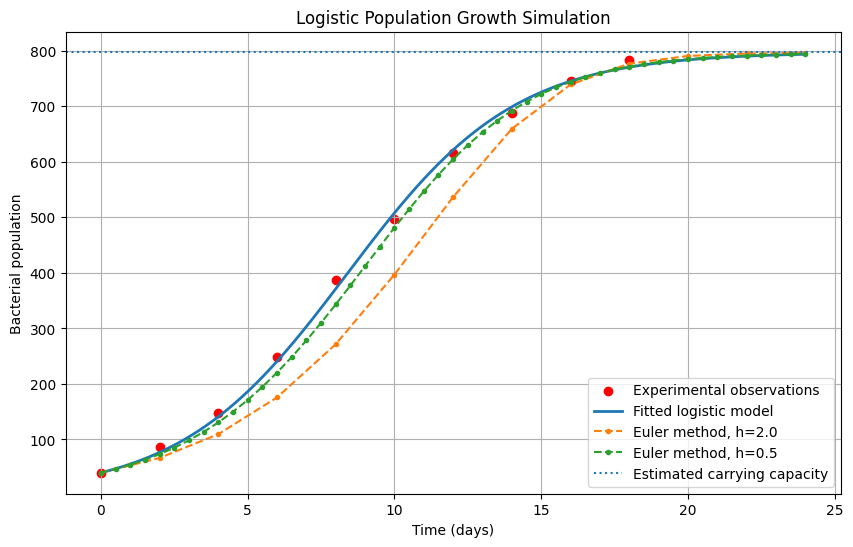

In [6]:
plt.figure(figsize=(10, 6))

# Plot the simulated experimental observations
plt.scatter(
    t_data, P_data,
    color="red",
    label="Experimental observations"
)

# Plot the fitted analytical logistic model
t_fine = np.linspace(0, 24, 300)

plt.plot(
    t_fine,
    logistic(t_fine, r_est, K_est),
    label="Fitted logistic model",
    linewidth=2
)

# Plot Euler approximations for two different step sizes
for h in [2.0, 0.5]:

    t, P = euler_method(
        r_est, K_est, P0, h, 24
    )

    plt.plot(
        t, P,
        "--",
        marker="o",
        markersize=3,
        label=f"Euler method, h={h}"
    )

# Show the estimated carrying capacity
plt.axhline(
    K_est,
    linestyle=":",
    label="Estimated carrying capacity"
)

plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Logistic Population Growth Simulation")

plt.legend()
plt.grid()
plt.show()

### How should we interpret the graph?

**1. The overall S-shaped curve**

The population initially grows slowly, then increases more rapidly, and finally slows as it approaches the carrying capacity.

**2. The red observations**

The points do not lie exactly on the fitted curve because random measurement noise was added.

**3. The fitted logistic model**

The smooth curve represents the model after estimating \(r\) and \(K\) from the simulated observations.

**4. The Euler approximations**

The dashed curves represent numerical solutions. They approximate the fitted analytical solution.

A smaller step size generally produces a closer approximation for this example.

**5. The horizontal carrying-capacity line**

The population approaches the estimated value of \(K\), but the mathematical solution does not reach it in a finite amount of time when the initial population is positive and below \(K\).

The graph illustrates how differential equations, numerical methods and data analysis can work together in scientific computing.

---

# Step 7. Estimate the time required to reach 90% of carrying capacity

Suppose the scientist wants to know:

> How many days will it take for the bacterial population to reach 90% of its estimated carrying capacity?

We can answer this question using the analytical solution.

## 7.1 Derive the formula

The analytical solution is

$$
P(t)=\frac{K}{1+Ae^{-rt}},
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

We want the population to reach 90% of the carrying capacity:

$$
P(t_{90})=0.9K.
$$

Substitute this into the logistic solution:

$$
0.9K=\frac{K}{1+Ae^{-rt_{90}}}.
$$

Divide both sides by \(K\):

$$
0.9=\frac{1}{1+Ae^{-rt_{90}}}.
$$

Take the reciprocal:

$$
\frac{1}{0.9}=1+Ae^{-rt_{90}}.
$$

Since $1/0.9=10/9$,

$$
Ae^{-rt_{90}}=\frac{1}{9}.
$$

Therefore,

$$
e^{-rt_{90}}=\frac{1}{9A}.
$$

Taking the natural logarithm:

$$
-rt_{90}=-\ln(9A).
$$

Hence,

$$
\boxed{
t_{90}=\frac{\ln(9A)}{r}
}
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

## 7.2 Use the estimated parameters

We substitute the estimated parameters $r_{\text{est}}$ and $K_{\text{est}}$ into the formula.

The result is an estimate of the time required to reach 90% of the fitted carrying capacity.

In [7]:
# Calculate A using the estimated carrying capacity
A = (K_est - P0) / P0

# Calculate the time to reach 90% of carrying capacity
t90 = np.log(9 * A) / r_est

print(
    "Time to reach 90% carrying capacity:",
    round(t90, 2),
    "days"
)

# Calculate the corresponding population level
P90 = 0.90 * K_est

print(
    "90% of estimated carrying capacity:",
    round(P90, 2),
    "bacteria"
)

Time to reach 90% carrying capacity: 14.66 days
90% of estimated carrying capacity: 717.47 bacteria


### Interpretation

The estimated time is approximately **14.66 days**.

This means that, according to the fitted logistic model, the population is predicted to reach 90% of its estimated carrying capacity after approximately 14.66 days.

This is a model-based prediction, not a guarantee of what would happen in an actual laboratory. Real bacterial populations may be affected by changes in temperature, nutrients, contamination and other environmental conditions.

---

# Step 8. Compare Euler errors for different step sizes

The final task is to investigate the accuracy of Euler's method.

Since we know the analytical solution of the fitted logistic model, we can calculate the exact model value at day 24:

$$
P_{\text{exact}}(24)
=
\frac{K_{\text{est}}}
{1+\left(\frac{K_{\text{est}}-P_0}{P_0}\right)
e^{-24r_{\text{est}}}}.
$$

We can then compare this value with the final Euler approximation.

## 8.1 Absolute error

The absolute error is defined as

$$
\boxed{
E=\left|P_{\text{Euler}}(24)-P_{\text{exact}}(24)\right|.
}
$$

This measures the absolute difference between the numerical approximation and the exact solution of the fitted model.

We repeat the calculation using

$$
h=2,\quad 1,\quad 0.5,\quad 0.1.
$$

All four step sizes divide the total interval of 24 days exactly, so the numerical approximations end at the same time.

In [8]:
# Calculate the exact analytical solution at day 24
T = 24

exact = logistic(T, r_est, K_est)

print("Exact fitted-model population at day 24:", round(exact, 4))
print()

# Compare Euler errors for different step sizes
step_sizes = [2, 1, 0.5, 0.1]
errors = []

for h in step_sizes:

    # Calculate the Euler approximation
    t, P = euler_method(r_est, K_est, P0, h, T)

    # Calculate absolute error at the final time
    error = abs(P[-1] - exact)

    errors.append(error)

    print(f"Step size h = {h:>3}: error = {error:.4f}")

Exact fitted-model population at day 24: 793.8426

Step size h =   2: error = 2.7581
Step size h =   1: error = 1.4395
Step size h = 0.5: error = 0.7181
Step size h = 0.1: error = 0.1425


## 8.2 Interpret the numerical errors

You should observe that the absolute error decreases as the step size becomes smaller.

For this simulated example, the errors are approximately:

| Step size $h$ | Absolute error at day 24 |
|---:|---:|
| 2.0 | 2.7581 |
| 1.0 | 1.4395 |
| 0.5 | 0.7181 |
| 0.1 | 0.1425 |

This illustrates an important principle of numerical analysis:

**Reducing the step size generally improves the accuracy of Euler's method for this problem.**

Euler's method is a first-order numerical method. Under suitable smoothness and stability conditions, its global error is proportional to the step size:

$$
E(h)=O(h).
$$

This means that, when the step size is sufficiently small, halving \(h\) will approximately halve the global error.

The relationship is an asymptotic result, not a guarantee for every step size or every differential equation.

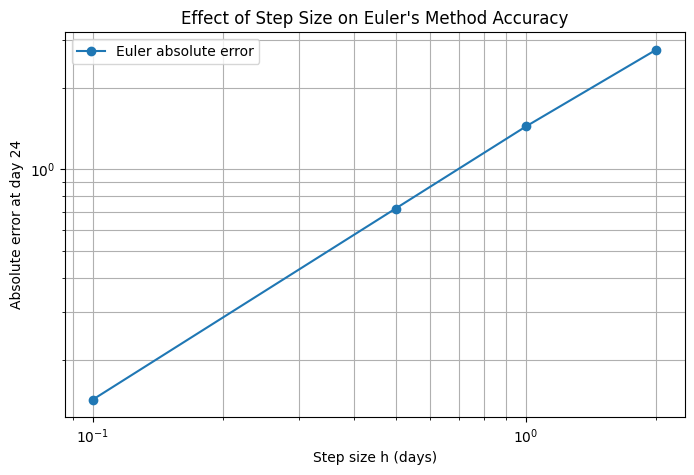

In [9]:
# Plot absolute error against step size
plt.figure(figsize=(8, 5))

plt.loglog(
    step_sizes,
    errors,
    "o-",
    label="Euler absolute error"
)

plt.xlabel("Step size h (days)")
plt.ylabel("Absolute error at day 24")
plt.title("Effect of Step Size on Euler's Method Accuracy")
plt.grid(True, which="both")
plt.legend()
plt.show()

---

# Step 9. Overall mathematical interpretation

We have now completed the bacterial growth investigation.

The workflow can be summarized as follows:

| Stage | Mathematical or computational idea | Purpose |
|---|---|---|
| 1 | Logistic differential equation | Describe population growth with limited resources |
| 2 | Analytical solution | Obtain an exact solution of the mathematical model |
| 3 | Simulated noisy observations | Represent imperfect experimental measurements |
| 4 | Nonlinear least squares | Estimate unknown parameters |
| 5 | Euler's method | Approximate the ODE numerically |
| 6 | Data visualization | Compare observations, fitted model and numerical solutions |
| 7 | Analytical prediction | Estimate the time to reach 90% of carrying capacity |
| 8 | Absolute error | Evaluate the accuracy of Euler's method |

## Connection to modern scientific computing

This small example introduces ideas used in contemporary scientific research.

**1. Data-driven modelling**

We used observations to estimate unknown model parameters.

**2. Inverse problems**

We started with data and recovered the parameters that could have generated the observations.

**3. Numerical simulation**

We used Euler's method to approximate the solution of a differential equation.

**4. Model validation**

We compared the numerical approximation with an analytical solution.

**5. Predictive modelling**

We used the fitted model to predict future population behaviour.

These ideas are building blocks for more advanced approaches such as scientific machine learning, physics-informed neural networks and neural ordinary differential equations.

> The important message is that modern scientific computing does not replace differential equations. It extends the ways in which we formulate, solve, estimate and investigate mathematical models.

---

# Step 10. Exercises for students

Try answering these questions after completing the notebook.

### Exercise 1: Effect of the growth rate

Keep $K=800$ and $P_0=40$, but change the growth rate to:

$$
r=0.20,\quad 0.35,\quad 0.50.
$$

**Questions:**

1. How does the growth rate affect the shape of the population curve?
2. Which value of $r$ produces the fastest growth?
3. Does changing $r$ change the carrying capacity?

### Exercise 2: Effect of the carrying capacity

Keep $r=0.35$ and $P_0=40$, but test:

$$
K=500,\quad 800,\quad 1200.
$$

**Questions:**

1. What happens to the final population level?
2. Does the population approach a different equilibrium?
3. How does the carrying capacity affect the population-growth curve?

### Exercise 3: Numerical accuracy

Run Euler's method using:

$$
h=2,\quad 1,\quad 0.5,\quad 0.25,\quad 0.1.
$$

**Questions:**

1. Which step size gives the smallest error?
2. Why does a smaller step size usually improve accuracy?
3. What is the disadvantage of using an extremely small step size?

### Exercise 4: Parameter estimation

Change the random seed from 12 to 25 and repeat the parameter estimation.

**Questions:**

1. Do you obtain exactly the same estimates?
2. Why do the estimates change?
3. What does this tell you about the effect of measurement noise?

### Exercise 5: Scientific interpretation

Suppose the fitted model predicts a carrying capacity of 800 bacteria, but the actual laboratory population stops growing at 600.

**Questions:**

1. What assumptions of the mathematical model might be incorrect?
2. What additional experimental information would you collect?
3. How could you improve the model?

---

## Final takeaway

The bacterial growth problem demonstrates the complete journey from a real-world question to a mathematical model, from the mathematical model to a numerical solution, and from observed data to parameter estimation and prediction.

It is a practical introduction to how differential equations and scientific computing are used together in mathematics, biology, engineering and modern scientific research.